In [ ]:
!pip install sentinelhub rasterio geopandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timedelta
from sentinelhub import (
    SHConfig, BBox, CRS, SentinelHubRequest, MimeType,
    DataCollection, bbox_to_dimensions, MosaickingOrder
)
from rasterio.transform import from_bounds
from google.colab import files

# === Sentinel Hub Config ===
config = SHConfig()
config.sh_client_id = ""
config.sh_client_secret = ""
config.download_timeout_seconds = 60

# === Region definitions ===
regions = {
    "Thar": [70.905, 26.906, 70.925, 26.924],
}

# === Date range for 4 years ===
start_date = datetime(2021, 6, 1)
end_date = datetime(2023, 6, 1)
date_list = [start_date + timedelta(days=i) for i in range((end_date - start_date).days + 1)]

# === Evalscript (7 bands) ===
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["B02", "B03", "B04", "B05", "B08", "B11", "B12"],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(sample) {
  return [
    sample.B02, sample.B03, sample.B04,
    sample.B05, sample.B08, sample.B11, sample.B12
  ];
}
"""

# === Data collection ===
all_data = []

for region_name, coords in regions.items():
    bbox = BBox(bbox=coords, crs=CRS.WGS84)
    size = bbox_to_dimensions(bbox, resolution=10)

    for date in date_list:
        date_str = date.strftime('%Y-%m-%d')
        print(f"\n📦 Fetching for {region_name} - {date_str}")
        try:
            request = SentinelHubRequest(
                evalscript=evalscript,
                input_data=[SentinelHubRequest.input_data(
                    data_collection=DataCollection.SENTINEL2_L2A,
                    time_interval=(date_str, date_str),
                    mosaicking_order=MosaickingOrder.MOST_RECENT
                )],
                responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
                bbox=bbox,
                size=size,
                config=config
            )

            images = request.get_data(save_data=False)
            if not images:
                print("⚠ No image returned.")
                continue

            image = images[0]
            blue, green, red, red_edge, nir, swir1, swir2 = image[:7]

            if np.all(nir == 0) or np.all(red == 0):
                print("⚠ Image is empty (all zeros). Skipping.")
                continue

            # Compute indices
            ndvi = (nir - red) / (nir + red + 1e-6)
            savi = (nir - red) * 1.5 / (nir + red + 0.5)
            ndmi = (nir - swir1) / (nir + swir1 + 1e-6)
            evi = 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1)
            revi = (red_edge - red) / (red_edge + red + 1e-6)

            transform = from_bounds(*bbox, width=ndvi.shape[1], height=ndvi.shape[0])
            for y in range(ndvi.shape[0]):
                for x in range(ndvi.shape[1]):
                    if np.isnan(ndvi[y, x]):
                        continue
                    lat, lon = rasterio.transform.xy(transform, y, x)
                    all_data.append({
                        "timestamp": date_str,
                        "region": region_name,
                        "latitude": lat,
                        "longitude": lon,
                        "ndvi": float(ndvi[y, x]),
                        "savi": float(savi[y, x]),
                        "ndmi": float(ndmi[y, x]),
                        "evi": float(evi[y, x]),
                        "revi": float(revi[y, x])
                    })

            print(f"✅ Done for {region_name} - {date_str}")

        except Exception as e:
            print(f"❌ Error for {region_name} - {date_str}: {e}")
            continue

# === Export to CSV ===
df = pd.DataFrame(all_data)
df.to_csv("XGboost_Desert_Validation_Model.csv", index=False)
files.download("XGboost_Desert_Validation_Model.csv")



📦 Fetching for Thar - 2021-06-01
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-02
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-03
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-04
✅ Done for Thar - 2021-06-04

📦 Fetching for Thar - 2021-06-05
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-06
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-07
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-08
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-09
✅ Done for Thar - 2021-06-09

📦 Fetching for Thar - 2021-06-10
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-11
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-12
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-13
⚠ Image is empty (all zeros). Skipping.

📦 Fetching for Thar - 2021-06-14
✅ Done for Thar - 2021-06-

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DATA PRE-PROCESSING

import pandas as pd
from google.colab import files

# Load the previously extracted file
df = pd.read_csv("XGboost_Desert_Validation_Model.csv")

# Drop rows with missing values
df = df.dropna()

# Convert columns to correct types
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
for col in ['latitude', 'longitude', 'ndvi', 'savi', 'ndmi', 'evi', 'revi']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filter out invalid NDVI values (e.g., zero or negative)
df = df[df['ndvi'] <= 1] # the range of ndvi > 0 is not ommitted to let the model check if ndvi == (-1) shows no crop growth

# Remove duplicates
df = df.drop_duplicates()

# Save cleaned file
df.to_csv("XGboost_Desert_Validation_Model_CLEANED.csv", index=False)
files.download("XGboost_Desert_Validation_Model_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Aggregated (non-pixelated) data for XGboost model

import pandas as pd
from google.colab import files

# Load the cleaned file with pixel-wise data
df = pd.read_csv("XGboost_Desert_Validation_Model_CLEANED.csv")

# Ensure timestamp is in datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp', 'region'])  # Ensure no missing region

# Create a 'date' column for daily aggregation
df['date'] = df['timestamp'].dt.date

# Group by both date and region
daily_avg = df.groupby(['date', 'region']).agg({
    'ndvi': 'mean',
    'savi': 'mean',
    'ndmi': 'mean',
    'evi': 'mean',
    'revi': 'mean'
}).reset_index()

# Save the aggregated data
daily_avg.to_csv("XGboost_Desert_Aggregated_Daily_VI.csv", index=False)
files.download("XGboost_Desert_Aggregated_Daily_VI.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df['timestamp'].dt.date.nunique())
print(sorted(df['timestamp'].dt.date.unique()))

146
[datetime.date(2021, 6, 4), datetime.date(2021, 6, 9), datetime.date(2021, 6, 14), datetime.date(2021, 6, 19), datetime.date(2021, 6, 24), datetime.date(2021, 6, 29), datetime.date(2021, 7, 4), datetime.date(2021, 7, 9), datetime.date(2021, 7, 14), datetime.date(2021, 7, 19), datetime.date(2021, 7, 24), datetime.date(2021, 7, 29), datetime.date(2021, 8, 3), datetime.date(2021, 8, 8), datetime.date(2021, 8, 13), datetime.date(2021, 8, 18), datetime.date(2021, 8, 23), datetime.date(2021, 8, 28), datetime.date(2021, 9, 2), datetime.date(2021, 9, 7), datetime.date(2021, 9, 12), datetime.date(2021, 9, 17), datetime.date(2021, 9, 22), datetime.date(2021, 9, 27), datetime.date(2021, 10, 2), datetime.date(2021, 10, 7), datetime.date(2021, 10, 12), datetime.date(2021, 10, 17), datetime.date(2021, 10, 22), datetime.date(2021, 10, 27), datetime.date(2021, 11, 1), datetime.date(2021, 11, 6), datetime.date(2021, 11, 11), datetime.date(2021, 11, 16), datetime.date(2021, 11, 21), datetime.date(20

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
from google.colab import files

# Load the aggregated file
df = pd.read_csv('XGboost_Desert_Aggregated_Daily_VI.csv')

# List of VI columns
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']

# === Sanity checks ===
# Replace inf/-inf with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop rows with NaNs in VI columns
df.dropna(subset=vi_columns, inplace=True)

# Optionally filter out extreme values (rare spikes)
for col in vi_columns:
    df = df[(df[col] > -5) & (df[col] < 5)]

# === Standardization ===
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip values between -1 and 1 (optional, for consistency)
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# === Export the result ===
df_scaled.to_csv('XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv', index=False)
files.download("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

print("✅ Standardization (Z-score) and clipping complete.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Standardization (Z-score) and clipping complete.


In [ ]:
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']].describe())
# to check if mean is approximately 0 == standardized data

             ndvi        savi        ndmi         evi        revi
count  146.000000  146.000000  146.000000  146.000000  146.000000
mean    -0.039165   -0.025485    0.012944   -0.009845    0.004658
std      0.669440    0.660129    0.669446    0.352905    0.642787
min     -1.000000   -1.000000   -1.000000   -1.000000   -1.000000
25%     -0.606916   -0.590502   -0.594615   -0.049547   -0.486876
50%     -0.062396   -0.074925    0.005894    0.023018    0.188739
75%      0.574456    0.552228    0.613473    0.111926    0.493630
max      1.000000    1.000000    1.000000    1.000000    1.000000


In [ ]:
!pip install xgboost

In [ ]:
# XGboost with threshold NDVI

import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# Load standardized data
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

# Label generation from NDVI
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# Encode labels: e.g., 'Delayed' → 0, 'Immature' → 1, etc.
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

# Features and encoded labels
# X = df[['ndvi']]  # Only NDVI
# X = df[['ndvi','savi', 'ndmi', 'evi', 'revi']]  # Use all VIs as input features
X = df[['savi', 'ndmi', 'evi', 'revi']]  # Use all VIs (except NDVI)as input features
y = df['label_encoded']

# Train/Validation/Test Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# XGBoost Classifier
model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
model.fit(X_train, y_train)

# Validation Report
print("📋 Validation Report:")
val_preds = model.predict(X_val)
print(classification_report(y_val, val_preds, target_names=le.classes_))

# Test Report
print("\n🧪 Test Report:")
test_preds = model.predict(X_test)
print(classification_report(y_test, test_preds, target_names=le.classes_))

from sklearn.metrics import accuracy_score

# Print final accuracy on test set
final_accuracy = accuracy_score(y_test, test_preds)
print(f"\n🎯 Final Accuracy on Test Set: {final_accuracy:.4f}")

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:59:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


📋 Validation Report:
               precision    recall  f1-score   support

      Delayed       0.94      0.89      0.92        19
Harvest-ready       1.00      0.86      0.92         7
     Immature       0.40      0.67      0.50         3

     accuracy                           0.86        29
    macro avg       0.78      0.81      0.78        29
 weighted avg       0.90      0.86      0.88        29


🧪 Test Report:
               precision    recall  f1-score   support

      Delayed       0.90      0.95      0.93        20
Harvest-ready       1.00      0.88      0.93         8
     Immature       0.50      0.50      0.50         2

     accuracy                           0.90        30
    macro avg       0.80      0.78      0.79        30
 weighted avg       0.90      0.90      0.90        30


🎯 Final Accuracy on Test Set: 0.9000


In [ ]:
# === XGBoost with Dynamic NDVI Labeling ===

import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Load standardized data
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

# Dynamic NDVI Thresholds
ndvi_min = df['ndvi'].min()
ndvi_max = df['ndvi'].max()

high_threshold = ndvi_min + 0.7 * (ndvi_max - ndvi_min)
low_threshold  = ndvi_min + 0.3 * (ndvi_max - ndvi_min)

# Label generation (Dynamic)
def label_crop_stage_dynamic(ndvi):
    if ndvi >= high_threshold:
        return 'Immature'
    elif ndvi <= low_threshold:
        return 'Harvest-ready'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage_dynamic)

# Encode labels
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

# Select input features
X = df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']]
# X = df[['savi', 'ndmi', 'evi', 'revi']]
y = df['label_encoded']

# Train/Validation/Test Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Train XGBoost Classifier
model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
model.fit(X_train, y_train)

# === Evaluation ===

# Validation Set Report
print("📋 Validation Report:")
val_preds = model.predict(X_val)
print(classification_report(y_val, val_preds, target_names=le.classes_))

# Test Set Report
print("\n🧪 Test Report:")
test_preds = model.predict(X_test)
print(classification_report(y_test, test_preds, target_names=le.classes_))

# Accuracy on test set
final_accuracy = accuracy_score(y_test, test_preds)
print(f"\n🎯 Final Accuracy on Test Set: {final_accuracy:.4f}")

📋 Validation Report:
               precision    recall  f1-score   support

      Delayed       1.00      1.00      1.00        10
Harvest-ready       1.00      1.00      1.00        10
     Immature       1.00      1.00      1.00         9

     accuracy                           1.00        29
    macro avg       1.00      1.00      1.00        29
 weighted avg       1.00      1.00      1.00        29


🧪 Test Report:
               precision    recall  f1-score   support

      Delayed       0.91      1.00      0.95        10
Harvest-ready       1.00      1.00      1.00        11
     Immature       1.00      0.89      0.94         9

     accuracy                           0.97        30
    macro avg       0.97      0.96      0.96        30
 weighted avg       0.97      0.97      0.97        30


🎯 Final Accuracy on Test Set: 0.9667


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:59:44] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


<Figure size 600x400 with 0 Axes>

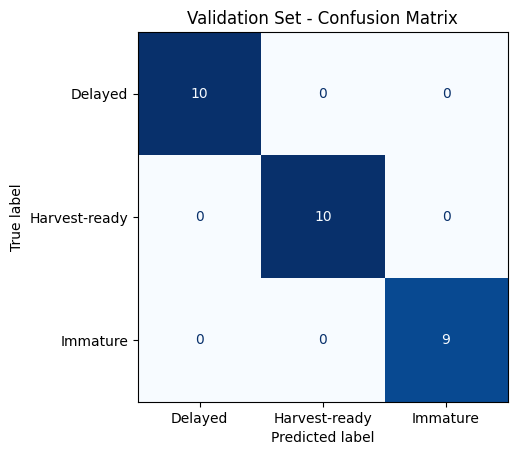

<Figure size 600x400 with 0 Axes>

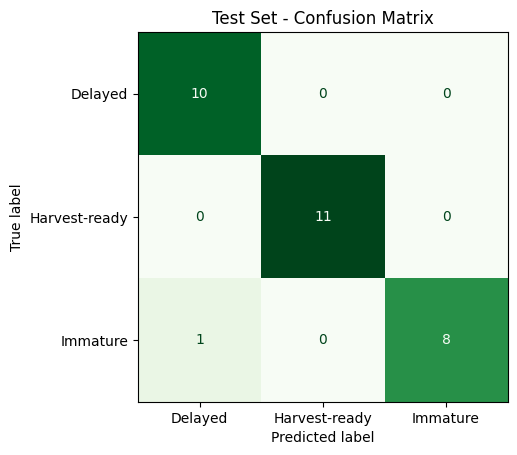

In [ ]:
# CONFUSION MATRIX FOR DYNAMIC NDVI

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict on Validation and Test Sets
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# Class labels (as integers): [0, 1, 2]
class_labels_encoded = [0, 1, 2]

# Use original label names for display
class_labels_str = le.classes_  # ['Delayed', 'Harvest-ready', 'Immature']

# Confusion Matrix for Validation Set
cm_val = confusion_matrix(y_val, y_val_pred, labels=class_labels_encoded)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=class_labels_str)

plt.figure(figsize=(6, 4))
disp_val.plot(cmap='Blues', colorbar=False)
plt.title("Validation Set - Confusion Matrix")
plt.show()

# Confusion Matrix for Test Set
cm_test = confusion_matrix(y_test, y_test_pred, labels=class_labels_encoded)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=class_labels_str)

plt.figure(figsize=(6, 4))
disp_test.plot(cmap='Greens', colorbar=False)
plt.title("Test Set - Confusion Matrix")
plt.show()

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [05:11:57] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/tmp/ipython-input-15-833471827.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  numeric_heatmap = heatmap_data.replace(label_to_int)


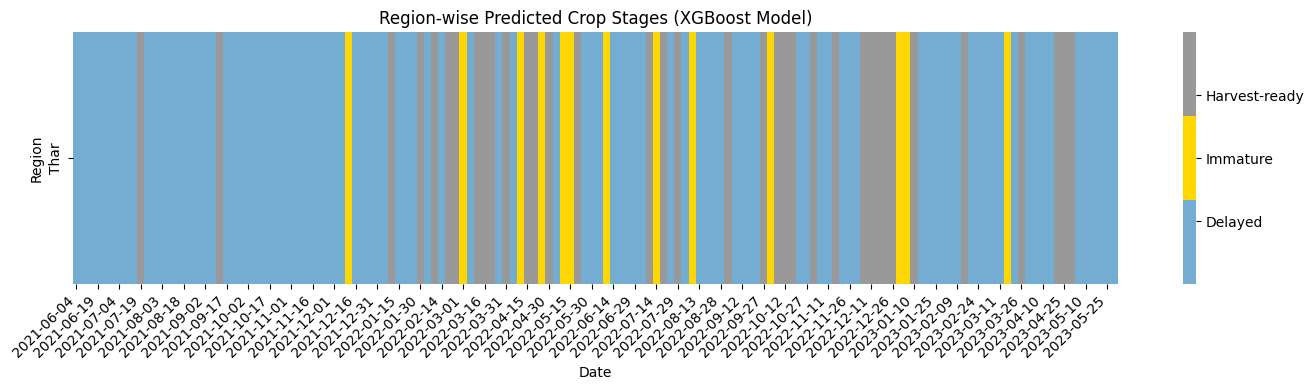

In [ ]:
# CLASSIFICATION MAP FOR THRESHOLD NDVI

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# === Load aggregated standardized CSV ===
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

# === Label NDVI-based crop stages
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# === Prepare features and target
features = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']
X = df[features]
y = df['label']

# === Encode labels for training
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# === Train the XGBoost model
model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
model.fit(X, y_encoded)

# === Predict crop stage using trained model
df['predicted_label_encoded'] = model.predict(X)
df['predicted_label'] = le.inverse_transform(df['predicted_label_encoded'])

# === Format 'date' column if not already
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['date_str'] = df['date'].dt.strftime('%Y-%m-%d')  # Optional clean label

# === Pivot for heatmap: Region vs Date with Predicted Labels
heatmap_data = df.pivot(index='region', columns='date_str', values='predicted_label')

# === Convert class labels to numbers for colormap
label_to_int = {'Delayed': 0, 'Immature': 1, 'Harvest-ready': 2}
int_to_label = {v: k for k, v in label_to_int.items()}
numeric_heatmap = heatmap_data.replace(label_to_int)

# === Plot heatmap
plt.figure(figsize=(14, 4))
sns.heatmap(numeric_heatmap, cmap=["#74add1", "#ffd700", "#999999"], cbar_kws={
    'ticks': [0.33, 1, 1.66],
    'format': '%d'
})
plt.title("Region-wise Predicted Crop Stages (XGBoost Model)")
plt.xlabel("Date")
plt.ylabel("Region")
plt.xticks(rotation=45, ha='right')

# Fix colorbar labels
colorbar = plt.gca().collections[0].colorbar
colorbar.set_ticks([0.5, 1, 1.5])
colorbar.set_ticklabels(['Delayed', 'Immature', 'Harvest-ready'])

plt.tight_layout()
plt.show()


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [06:19:59] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/tmp/ipython-input-18-112601658.py:47: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  numeric_heatmap = heatmap_data.replace(label_to_int)


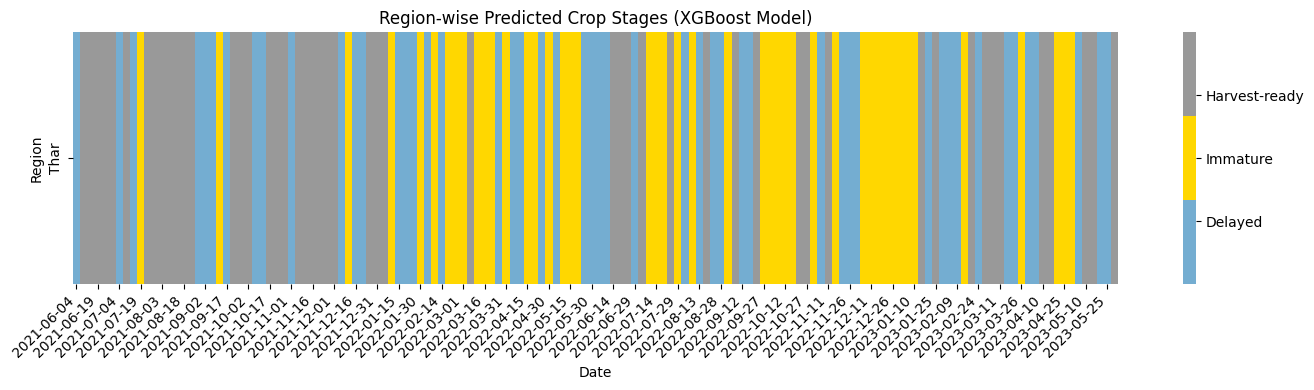

In [ ]:
# CLASSIFICATION MAP FOR DYNAMIC NDVI

# === Load Data ===
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

# === Dynamic NDVI Thresholds ===
ndvi_min = df['ndvi'].min()
ndvi_max = df['ndvi'].max()

high_threshold = ndvi_min + 0.7 * (ndvi_max - ndvi_min)
low_threshold  = ndvi_min + 0.3 * (ndvi_max - ndvi_min)

# === Label Crop Stage Dynamically ===
def label_crop_stage_dynamic(ndvi):
    if ndvi >= high_threshold:
        return 'Immature'
    elif ndvi <= low_threshold:
        return 'Harvest-ready'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage_dynamic)

# === Train Model (if not already trained) ===
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

X = df[['savi', 'ndmi', 'evi', 'revi']]
le = LabelEncoder()
y = le.fit_transform(df['label'])

model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
model.fit(X, y)

# === Prediction for the Map ===
df['predicted_label'] = le.inverse_transform(model.predict(X))


# === Format 'date' column if not already
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['date_str'] = df['date'].dt.strftime('%Y-%m-%d')  # Optional clean label

# === Pivot for heatmap: Region vs Date with Predicted Labels
heatmap_data = df.pivot(index='region', columns='date_str', values='predicted_label')

# === Convert class labels to numbers for colormap
label_to_int = {'Delayed': 0, 'Immature': 1, 'Harvest-ready': 2}
int_to_label = {v: k for k, v in label_to_int.items()}
numeric_heatmap = heatmap_data.replace(label_to_int)

# === Plot heatmap
plt.figure(figsize=(14, 4))
sns.heatmap(numeric_heatmap, cmap=["#74add1", "#ffd700", "#999999"], cbar_kws={
    'ticks': [0.33, 1, 1.66],
    'format': '%d'
})
plt.title("Region-wise Predicted Crop Stages (XGBoost Model)")
plt.xlabel("Date")
plt.ylabel("Region")
plt.xticks(rotation=45, ha='right')

# Fix colorbar labels
colorbar = plt.gca().collections[0].colorbar
colorbar.set_ticks([0.5, 1, 1.5])
colorbar.set_ticklabels(['Delayed', 'Immature', 'Harvest-ready'])

plt.tight_layout()
plt.show()

/tmp/ipython-input-21-2621594875.py:39: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


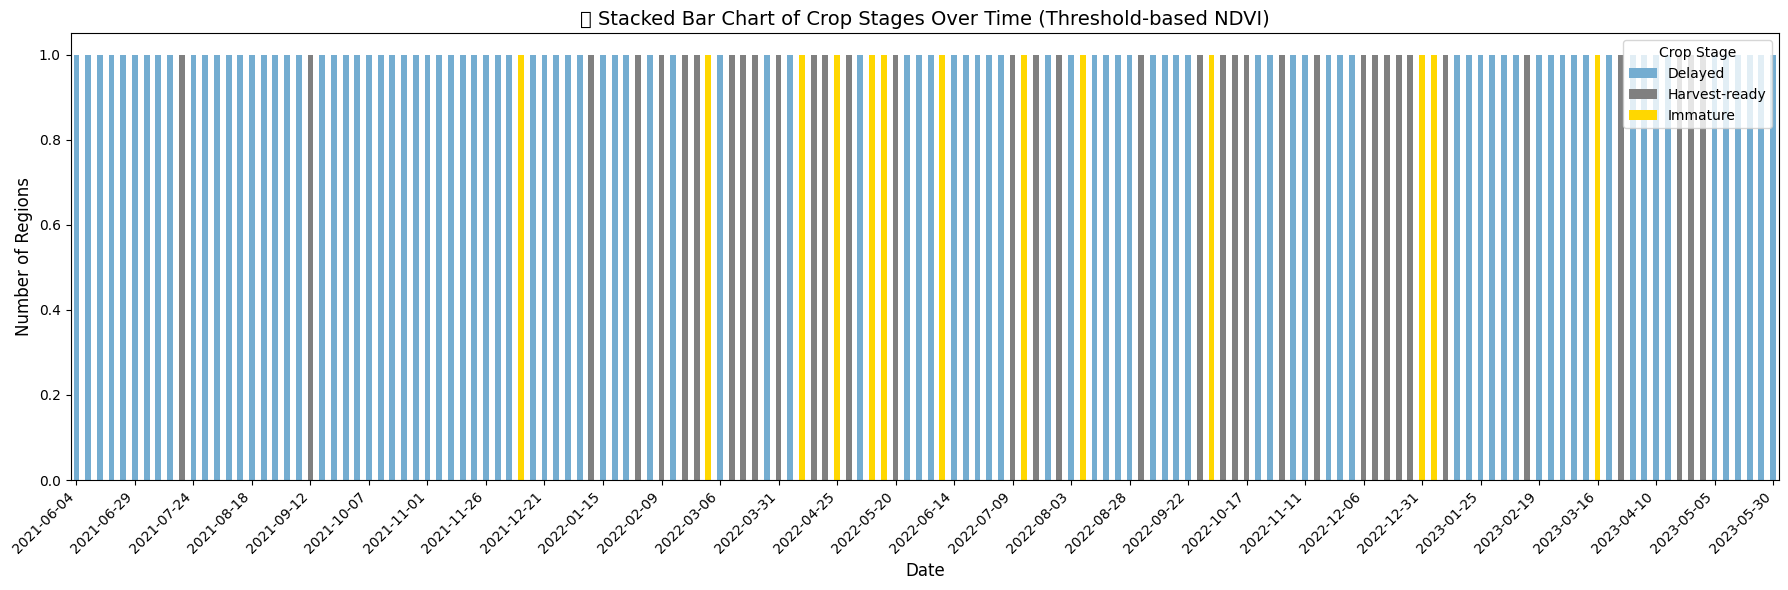

In [ ]:
# STACKED BAR CHART FOR THRESHOLD NDVI

import pandas as pd
import matplotlib.pyplot as plt

# Load your prediction results
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI_STANDARDIZED.csv")

# If labels not already assigned, apply NDVI-based crop stage logic
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# Group by date and crop stage
grouped = df.groupby(['date', 'label']).size().unstack(fill_value=0)

# Sort by date
grouped = grouped.sort_index()

# Create the plot
fig, ax = plt.subplots(figsize=(18, 6))

grouped.plot(kind='bar', stacked=True, ax=ax,
             color={'Delayed': '#74add1', 'Immature': 'gold', 'Harvest-ready': 'gray'})

# Improve date visibility
ax.set_xticks(range(0, len(grouped.index), max(1, len(grouped.index) // 25)))  # limit ticks
ax.set_xticklabels(grouped.index[::max(1, len(grouped.index) // 25)], rotation=45, ha='right')

# Titles and labels
plt.title("Stacked Bar Chart of Crop Stages Over Time (Threshold-based NDVI)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Number of Regions", fontsize=12)
plt.legend(title="Crop Stage")
plt.tight_layout()
plt.show()

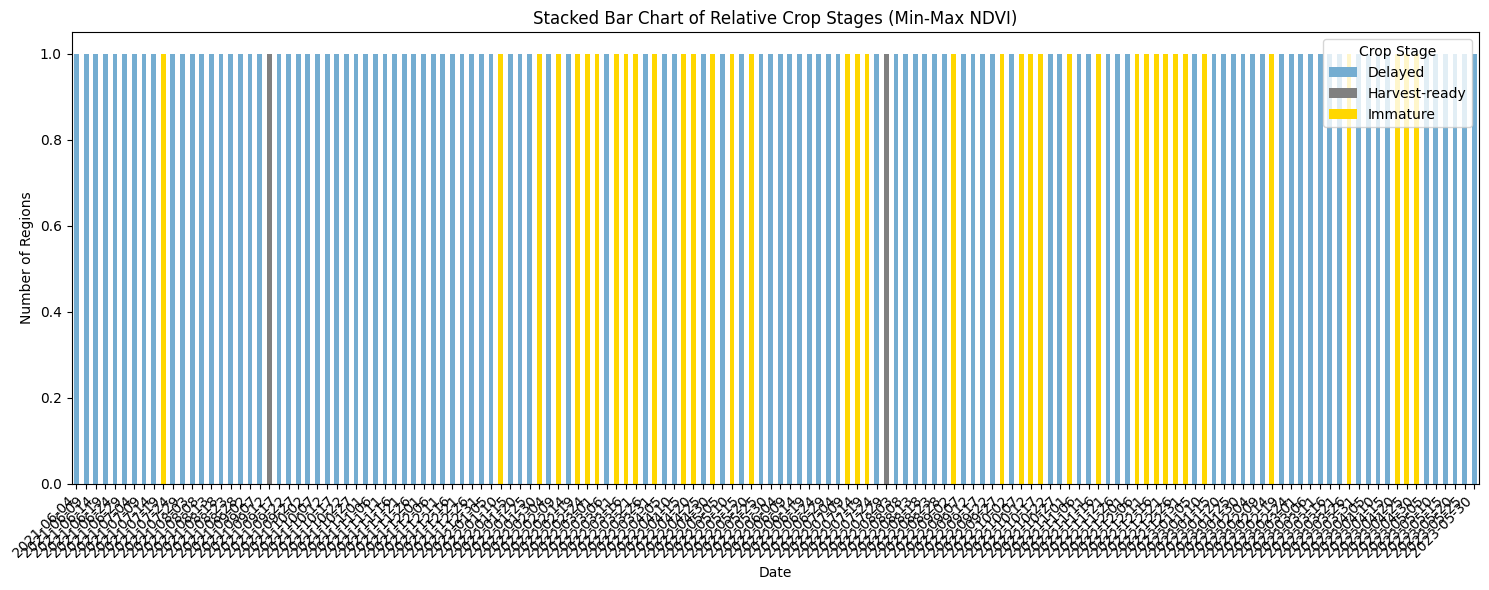

In [ ]:
# STACKED BAR CHART FOR DYNAMIC NDVI

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the aggregated file
df = pd.read_csv("XGboost_Desert_Aggregated_Daily_VI.csv")

# 1. Compute NDVI min/max
ndvi_min = df['ndvi'].min()
ndvi_max = df['ndvi'].max()

# 2. Calculate scaled NDVI between 0 and 1
df['ndvi_scaled'] = (df['ndvi'] - ndvi_min) / (ndvi_max - ndvi_min)

# 3. Label based on relative thirds
def label_relative(ndvi):
    if ndvi > 2/3:
        return 'Harvest-ready'
    elif ndvi > 1/3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi_scaled'].apply(label_relative)

# 4. Group by date and label count
grouped = df.groupby(['date', 'label']).size().unstack(fill_value=0)

# 5. Plot stacked bar chart
grouped = grouped.sort_index()
grouped.plot(kind='bar', stacked=True, figsize=(15, 6),
             color={'Delayed': '#74add1', 'Immature': 'gold', 'Harvest-ready': 'gray'})

plt.title("Stacked Bar Chart of Relative Crop Stages (Min-Max NDVI)")
plt.xlabel("Date")
plt.ylabel("Number of Regions")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Crop Stage")
plt.tight_layout()
plt.show()

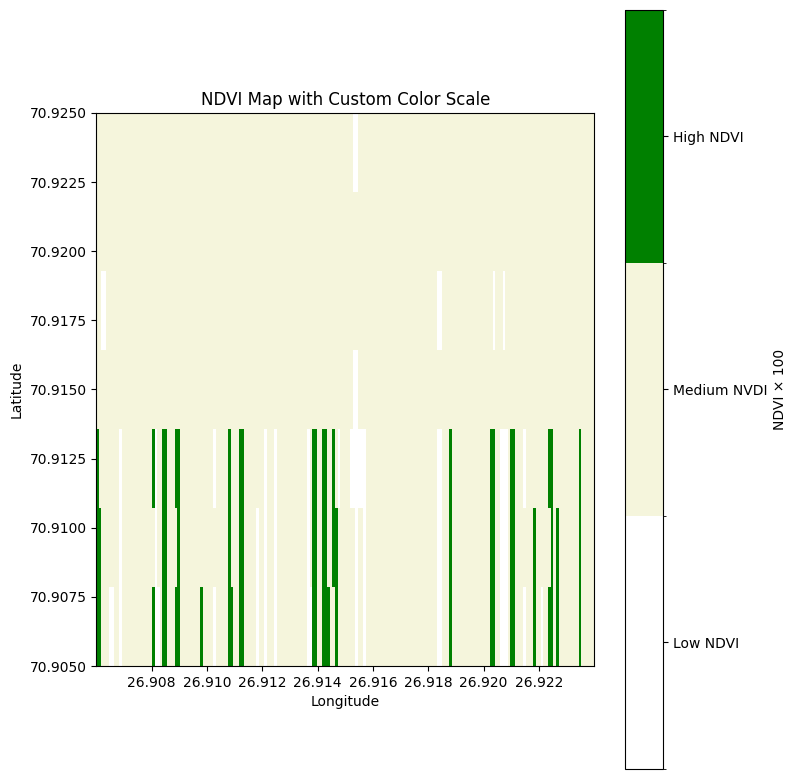

In [ ]:
# HEAT MAP FOR ONLY NDVI (NO ML MODEL)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Load and prepare data
df = pd.read_csv("XGboost_Desert_Validation_Model_CLEANED.csv")  # Replace with actual filename
df['latitude'] = df['latitude'].round(5)
df['longitude'] = df['longitude'].round(5)
df['ndvi'] = pd.to_numeric(df['ndvi'], errors='coerce')

# Pivot to grid and scale NDVI
ndvi_grid = df.pivot_table(index='latitude', columns='longitude', values='ndvi', aggfunc='mean')
ndvi_scaled = ndvi_grid * 100  # Amplify for visibility

# Define custom colormap
colors = ["white", "beige", "green"]
bounds = [-30, -10, 10, 30]
cmap = ListedColormap(colors)
norm = BoundaryNorm(bounds, cmap.N)

# Plot the map
plt.figure(figsize=(8, 8))
im = plt.pcolormesh(ndvi_scaled.columns.values,
                    ndvi_scaled.index.values,
                    ndvi_scaled.values,
                    cmap=cmap,
                    norm=norm,
                    shading='auto')

# Add colorbar
cbar = plt.colorbar(im, boundaries=bounds, ticks=[-20, 0, 20])
cbar.ax.set_yticklabels(['Low NDVI', 'Medium NVDI', 'High NDVI'])
cbar.set_label("NDVI × 100")

# Labels and appearance
plt.title("NDVI Map with Custom Color Scale")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()
